In [1]:
# Imports
import pandas as pd
import numpy as np
import duckdb
import joblib

In [2]:
# Define features (purposely exclude swing)
base = ["balls", "strikes", "outs_when_up", "p_throws", "stand", "on_1b", "on_2b", "on_3b", "plate_x", "z_diff"]
w_pitch = ["release_speed", "release_pos_x", "release_pos_z", "pfx_x", "pfx_z", "release_spin_rate", "release_extension"]

target = "delta_run_exp"

# Load Test Data

In [3]:
# Use DuckDB to read SQL queries
test_query = """
    SELECT
        *
    FROM
        data.parquet
    WHERE
        game_year = 2026
"""
df = duckdb.sql(test_query).df()

In [6]:
df = df.dropna().copy()

In [7]:
len(df)

724186

# Load Swing Probability Model

In [8]:
swing_prob_model = joblib.load("swing_probability_model.pkl")

# Predict Probabilities of Swings

In [11]:
df["swing_prob"] = swing_prob_model.predict_proba(df[base + w_pitch])[:,1]

In [14]:
df[['game_date', 'batter_name', 'player_name', 'pitch_type', 'inning', 'balls', 'strikes', 'outs_when_up', 
    'on_1b', 'on_2b', 'on_3b', 'plate_x', 'z_diff', 'swing', 'swing_prob']].sort_values("swing_prob", ascending=False)

,game_date,batter_name,player_name,pitch_type,inning,balls,strikes,outs_when_up,on_1b,on_2b,on_3b,plate_x,z_diff,swing,swing_prob
712863,2026-03-29,Carlos Correa,"Kochanowicz, Jack",SI,2,3,2,0,0,0,0,-0.640018,-0.815446,1,0.994903
674140,2026-04-08,Joey Bart,"King, Michael",CH,5,2,2,0,0,0,0,-0.479627,-0.753192,1,0.994742
262633,2026-07-26,Freddie Freeman,"Peralta, Freddy",CH,1,3,2,1,0,1,0,-0.525276,-0.722999,1,0.994736
7895,2026-10-03,Junior Caminero,"Cole, Gerrit",CH,5,3,2,2,0,0,0,-0.375619,-0.767822,1,0.994643
467305,2026-05-31,Mj Melendez,"Sanoja, Javier",FA,8,2,2,0,0,0,0,-0.580075,-0.749918,1,0.994638
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
366066,2026-06-27,Joc Pederson,"Cease, Dylan",FF,5,0,2,0,0,0,0,-2.713367,2.701716,0,0.000003
328631,2026-07-06,Tommy Troy,"Buehler, Walker",SI,2,0,0,1,0,0,0,2.275637,1.107439,0,0.000003
543588,2026-05-12,Henry Davis,"Vodnik, Victor",CH,7,2,1,1,1,0,0,2.223580,2.507289,0,0.000003
271802,2026-07-24,Jung Hoo Lee,"Zeferjahn, Ryan",FF,9,1,2,0,0,0,0,-3.780670,5.402002,0,0.000002


<Axes: >

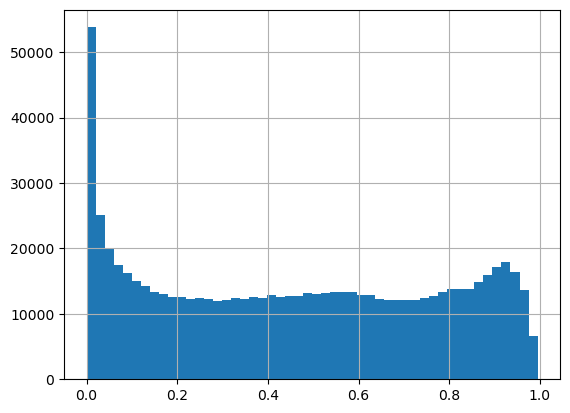

In [15]:
df["swing_prob"].hist(bins=50)

# Load DRE Model

In [16]:
model = joblib.load("swing_decision_model.pkl")

# Predict

In [17]:
df

,game_year,game_date,bat_team,batter_name,batter,pitch_team,player_name,pitcher,pitch_type,inning,...,release_pos_z,pfx_x,pfx_z,release_spin_rate,release_extension,swing,opp_swing,delta_run_exp,__index_level_0__,swing_prob
0,2026,2026-10-28,TB,Richie Palacios,680700,MIL,"Megill, Trevor",656730,FF,9,...,6.54,-0.02,1.57,2407,6.8,1,0,-0.283,3863310,0.813943
1,2026,2026-10-28,TB,Richie Palacios,680700,MIL,"Megill, Trevor",656730,KC,9,...,6.46,-0.01,-0.23,2883,6.6,0,1,0.024,3863311,0.141753
2,2026,2026-10-28,TB,Richie Palacios,680700,MIL,"Megill, Trevor",656730,FF,9,...,6.55,-0.35,1.75,2458,6.7,0,1,0.027,3863312,0.186763
3,2026,2026-10-28,TB,Richie Palacios,680700,MIL,"Megill, Trevor",656730,FF,9,...,6.59,-0.31,1.72,2471,6.6,0,1,-0.041,3863313,0.629833
4,2026,2026-10-28,TB,Chandler Simpson,802415,MIL,"Megill, Trevor",656730,FF,9,...,6.54,-0.29,1.77,2464,6.6,1,0,0.914,3863314,0.320038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725623,2026,2026-03-25,NYY,Trent Grisham,663757,SF,"Webb, Logan",657277,CH,1,...,4.78,-0.99,-0.43,1491,7.0,1,0,0.000,4591648,0.765160
725624,2026,2026-03-25,NYY,Trent Grisham,663757,SF,"Webb, Logan",657277,CH,1,...,4.81,-1.11,-0.55,1582,6.8,1,0,0.000,4591649,0.952366
725625,2026,2026-03-25,NYY,Trent Grisham,663757,SF,"Webb, Logan",657277,FF,1,...,5.04,-1.04,0.80,2062,6.9,0,1,0.024,4591650,0.099079
725626,2026,2026-03-25,NYY,Trent Grisham,663757,SF,"Webb, Logan",657277,CH,1,...,4.83,-0.95,-0.66,1577,6.8,1,0,-0.060,4591651,0.773460


In [18]:
X = df[base + ["swing"] + w_pitch]

# Predict change in run expectancy if hitter swung at pitch
X_swing = X.copy()
X_swing["swing"] = 1
df["xDRE_swing"] = model.predict(X_swing)

# Predict change in run expectancy if hitter didn't swing at pitch
X_no_swing = X.copy()
X_no_swing["swing"] = 0
df["xDRE_noswing"] = model.predict(X_no_swing)

# Corresponding xDRE based on hitter swung or not
df["xDRE_actual"] = np.where(df["swing"] == 1, df["xDRE_swing"], df["xDRE_noswing"])

In [19]:
# Average hitter's xDRE for pitch
df["xDRE_expected"] = df["swing_prob"] * df["xDRE_swing"] + (1 - df["swing_prob"]) * df["xDRE_noswing"]

# Difference between what hitter did and what average hitter would do
df["swing_decision_value"] = df["xDRE_actual"] - df["xDRE_expected"]

In [21]:
df[['game_date', 'batter_name', 'player_name', 'pitch_type', 'inning', 'balls', 'strikes', 'outs_when_up', 
    'on_1b', 'on_2b', 'on_3b', 'plate_x', 'z_diff', 'swing', 'swing_prob', 'delta_run_exp', 'xDRE_expected', 'swing_decision_value']].sort_values("swing_decision_value", ascending=False)

,game_date,batter_name,player_name,pitch_type,inning,balls,strikes,outs_when_up,on_1b,on_2b,on_3b,plate_x,z_diff,swing,swing_prob,delta_run_exp,xDRE_expected,swing_decision_value
427573,2026-06-10,Byron Buxton,"Valdez, Framber",CH,1,3,2,1,0,0,0,0.257403,0.572051,0,0.808725,0.320,-0.102967,0.419026
588944,2026-04-30,Adolis García,"Winn, Keaton",FS,8,3,2,0,0,0,0,0.271695,0.642212,0,0.743813,0.366,-0.081596,0.418813
717789,2026-03-28,Marcell Ozuna,"Peterson, David",CH,4,3,2,0,1,0,0,0.809512,0.382209,0,0.822004,0.319,-0.095498,0.417166
710377,2026-03-30,Ramón Laureano,"Roupp, Landen",CH,5,3,2,1,0,0,0,-0.093833,0.570907,0,0.823395,0.312,-0.097066,0.416287
226685,2026-08-04,Jj Bleday,"Ginn, J.T.",CH,4,3,2,1,0,0,0,0.328026,0.675967,0,0.756281,0.324,-0.088079,0.406180
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
238638,2026-08-01,Jorge Soler,"Gasser, Robert",ST,4,3,2,0,0,0,0,-2.063954,1.127492,1,0.095904,-0.270,0.323151,-0.582172
13918,2026-09-27,Victor Mesa,"Wheeler, Zack",FS,1,3,2,0,0,0,0,1.303548,0.790396,1,0.053863,-0.330,0.321645,-0.585156
377590,2026-06-24,James Wood,"Nola, Aaron",KC,3,3,2,0,0,0,0,1.771150,0.727066,1,0.089136,-0.381,0.329552,-0.587784
617516,2026-04-22,Kyle Isbel,"Nunez, Anthony",CH,9,3,2,1,0,0,0,1.387523,1.483433,1,0.034799,-0.337,0.303741,-0.608553


<Axes: >

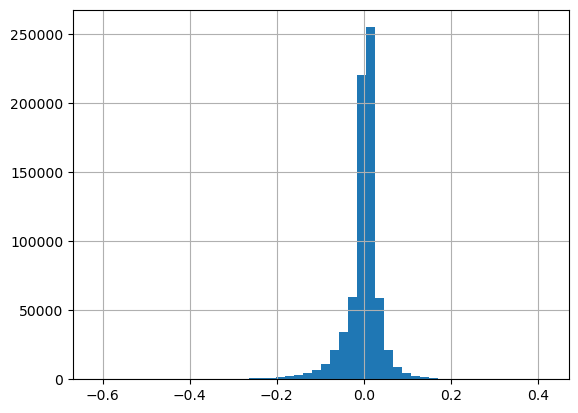

In [27]:
df["swing_decision_value"].hist(bins=50)

# Find Batters' Total Performances

In [22]:
bat = df.groupby("batter").agg(
    batter_name = ("batter_name", "first"),
    team = ("bat_team", "first"),
    pitches = ("batter", "count"),
    swing_decision_value = ("swing_decision_value", "mean")
).reset_index()

In [23]:
bat[bat["pitches"] >= 500].sort_values("swing_decision_value", ascending=False)

,batter,batter_name,team,pitches,swing_decision_value
571,695670,Harry Ford,WSH,524,0.007613
126,650402,Gleyber Torres,DET,1774,0.006954
74,621493,Taylor Ward,SEA,2507,0.006806
252,668885,Austin Martin,MIN,1382,0.006347
634,805808,Kevin Mcgonigle,DET,2828,0.006301
...,...,...,...,...,...
427,682657,Angel Martínez,CLE,1575,-0.010993
87,624641,Edmundo Sosa,PHI,913,-0.011262
315,671739,Michael Harris,ATL,2308,-0.011499
583,699302,Héctor Rodríguez,CIN,560,-0.011588


In [37]:
qual = bat["pitches"] >= 500
mean, std = bat.loc[qual, "swing_decision_value"].agg(["mean", "std"])
bat["SDV+"] = (100 + 10 * (bat["swing_decision_value"] - mean) / std).round().astype("int64")

In [38]:
bat[bat["team"] == "BOS"].sort_values("SDV+", ascending=False)

,batter,batter_name,team,pitches,swing_decision_value,SDV+
381,678554,Curtis Mead,BOS,1400,0.002746,112
132,655316,Andruw Monasterio,BOS,1502,0.002155,110
414,681508,Mickey Gasper,BOS,860,0.001741,109
161,663330,Jahmai Jones,BOS,715,0.001440,108
374,678011,Anthony Seigler,BOS,648,0.000978,107
106,642201,Eli White,BOS,802,0.000803,106
608,702332,Caleb Durbin,BOS,2182,0.000223,105
182,663853,Romy Gonzalez,BOS,288,0.000330,105
594,701350,Roman Anthony,BOS,965,-0.000421,103
256,668939,Adley Rutschman,BOS,1745,-0.000838,102


In [41]:
bat[bat["pitches"] >= 500].sort_values("SDV+", ascending=False)

,batter,batter_name,team,pitches,swing_decision_value,SDV+
571,695670,Harry Ford,WSH,524,0.007613,125
126,650402,Gleyber Torres,DET,1774,0.006954,123
74,621493,Taylor Ward,SEA,2507,0.006806,123
252,668885,Austin Martin,MIN,1382,0.006347,122
377,678246,Miguel Vargas,CWS,2909,0.006026,121
...,...,...,...,...,...,...
427,682657,Angel Martínez,CLE,1575,-0.010993,73
87,624641,Edmundo Sosa,PHI,913,-0.011262,72
315,671739,Michael Harris,ATL,2308,-0.011499,72
583,699302,Héctor Rodríguez,CIN,560,-0.011588,71


In [42]:
bat[bat["pitches"] >= 500].sort_values("SDV+", ascending=False).head(25)

,batter,batter_name,team,pitches,swing_decision_value,SDV+
571,695670,Harry Ford,WSH,524,0.007613,125
126,650402,Gleyber Torres,DET,1774,0.006954,123
74,621493,Taylor Ward,SEA,2507,0.006806,123
252,668885,Austin Martin,MIN,1382,0.006347,122
377,678246,Miguel Vargas,CWS,2909,0.006026,121
634,805808,Kevin Mcgonigle,DET,2828,0.006301,121
247,668709,Jj Bleday,CIN,2145,0.005676,120
39,593428,Xander Bogaerts,SD,2470,0.005614,120
16,543807,George Springer,TOR,2033,0.005726,120
210,665742,Juan Soto,NYM,1848,0.005486,119


In [51]:
bat.sort_values("pitches", ascending=False).head(10)

,batter,batter_name,team,pitches,swing_decision_value,SDV+
255,668930,Brice Turang,MIL,3104,0.001484,108
143,656941,Kyle Schwarber,PHI,3046,0.000133,104
76,621566,Matt Olson,ATL,3021,-0.000914,101
303,670623,Isaac Paredes,HOU,2964,0.000696,106
514,691406,Junior Caminero,TB,2925,-0.004098,92
518,691718,Pete Crow-Armstrong,CHC,2913,-0.005412,89
377,678246,Miguel Vargas,CWS,2909,0.006026,121
330,672695,Geraldo Perdomo,AZ,2883,0.002754,112
306,671056,Iván Herrera,STL,2871,-0.000713,102
81,624413,Pete Alonso,BAL,2856,-0.000237,103


# Find Pitchers' Total Performances

In [43]:
pitch = df.groupby("pitcher").agg(
    pitcher_name = ("player_name", "first"),
    team = ("pitch_team", "first"),
    pitches = ("batter", "count"),
    swing_decision_value = ("swing_decision_value", "mean")
).reset_index()

In [44]:
pitch[pitch["pitches"] >= 500].sort_values("swing_decision_value")

,pitcher,pitcher_name,team,pitches,swing_decision_value
769,695243,"Miller, Mason",SD,1229,-0.009109
264,662253,"Muñoz, Andrés",SEA,953,-0.007897
222,656546,"Hoffman, Jeff",MIN,1210,-0.007601
698,689296,"Nunez, Anthony",BAL,993,-0.007575
849,805427,"Sommers, Drew",DET,642,-0.007367
...,...,...,...,...,...
248,657612,"Hill, Tim",NYY,816,0.003169
473,676254,"Walker, Ryan",SF,598,0.003663
609,683175,"Phillips, Connor",CIN,590,0.003693
352,668674,"Erceg, Lucas",KC,901,0.004527


In [45]:
# Convert to plus stat
qual = pitch["pitches"] >= 500
mean, std = pitch.loc[qual, "swing_decision_value"].agg(["mean", "std"])
pitch["SDV+"] = (100 - 10 * (pitch["swing_decision_value"] - mean) / std).round().astype("int64")

In [46]:
pitch[pitch["team"] == "BOS"].sort_values("SDV+", ascending=False)

,pitcher,pitcher_name,team,pitches,swing_decision_value,SDV+
644,686747,"La Sorsa, Joe",BOS,8,-0.014588,163
482,676477,"Whitlock, Garrett",BOS,778,-0.007193,128
261,661527,"Martinez, Seth",BOS,22,-0.006739,125
672,687562,"Bennett, Jake",BOS,1618,-0.003946,112
278,663558,"Morán, Jovani",BOS,1061,-0.003893,112
422,670912,"Oviedo, Johan",BOS,72,-0.003369,109
638,686580,"Slaten, Justin",BOS,508,-0.003372,109
834,801139,"Tolle, Payton",BOS,2358,-0.003227,109
61,594027,"Guerrero, Tyron",BOS,607,-0.003086,108
29,547973,"Chapman, Aroldis",BOS,855,-0.002738,106


In [47]:
pitch[pitch["pitches"] >= 500].sort_values("SDV+", ascending=False)

,pitcher,pitcher_name,team,pitches,swing_decision_value,SDV+
769,695243,"Miller, Mason",SD,1229,-0.009109,137
264,662253,"Muñoz, Andrés",SEA,953,-0.007897,131
222,656546,"Hoffman, Jeff",MIN,1210,-0.007601,129
698,689296,"Nunez, Anthony",BAL,993,-0.007575,129
849,805427,"Sommers, Drew",DET,642,-0.007367,128
...,...,...,...,...,...,...
248,657612,"Hill, Tim",NYY,816,0.003169,78
473,676254,"Walker, Ryan",SF,598,0.003663,76
609,683175,"Phillips, Connor",CIN,590,0.003693,76
352,668674,"Erceg, Lucas",KC,901,0.004527,72


In [50]:
pitch[pitch["pitches"] >= 500].sort_values("SDV+", ascending=False).head(25)

,pitcher,pitcher_name,team,pitches,swing_decision_value,SDV+
769,695243,"Miller, Mason",SD,1229,-0.009109,137
264,662253,"Muñoz, Andrés",SEA,953,-0.007897,131
222,656546,"Hoffman, Jeff",MIN,1210,-0.007601,129
698,689296,"Nunez, Anthony",BAL,993,-0.007575,129
849,805427,"Sommers, Drew",DET,642,-0.007367,128
213,656240,"Blewett, Scott",ATH,584,-0.007258,128
482,676477,"Whitlock, Garrett",BOS,778,-0.007193,128
228,656641,"Latz, Jacob",TEX,1128,-0.007069,127
498,676742,"Sanders, Cam",BAL,545,-0.006145,123
602,682989,"Mederos, Victor",ATL,597,-0.006042,122


In [52]:
pitch.sort_values("pitches", ascending=False).head(10)

,pitcher,pitcher_name,team,pitches,swing_decision_value,SDV+
188,642547,"Peralta, Freddy",TB,3304,-0.002894,107
197,645261,"Alcantara, Sandy",MIA,3293,0.000595,91
206,650911,"Sánchez, Cristopher",PHI,3274,-0.002424,105
360,668909,"Williams, Gavin",CLE,3240,-0.003800,111
831,800048,"Messick, Parker",CLE,3231,-0.003629,111
735,693645,"Schlittler, Cam",NYY,3198,-0.005289,118
204,650633,"King, Michael",SD,3190,-0.001932,103
547,680732,"Burke, Sean",CWS,3104,-0.002139,104
59,593958,"Rodriguez, Eduardo",AZ,3066,0.001899,84
50,592332,"Gausman, Kevin",CHC,3057,-0.001362,100
